# Your first Structure

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dschick/udkm1Dsim/blob/develop/examples/01-basics/01-structure.ipynb)

In order to carry out any simulations using the **udkm1Dsim** package, an according one-dimensional {py:class}`Structure <udkm1Dsim.structures.structure.Structure>` needs to be created in advance.

This {py:class}`Structure <udkm1Dsim.structures.structure.Structure>` object can consist of one or many sub-structures and/or {py:class}`Layers <udkm1Dsim.structures.layers.Layer>` of type {py:class}`UnitCell <udkm1Dsim.structures.layers.UnitCell>` or {py:class}`AmorphousLayer <udkm1Dsim.structures.layers.AmorphousLayer>`.

{py:class}`UnitCell <udkm1Dsim.structures.layers.UnitCell>`s consist of the fundamental building blocks, namely {py:class}`Atom <udkm1Dsim.structures.atoms.Atom>`s and {py:class}`AtomMixed <udkm1Dsim.structures.atoms.AtomMixed>`.

In this example the basic concepts of creating the above mentioned objects are introduced. Furthermore one should easily see how to set and access all the physical properties of these physical objects.

:::{tip}
All objects of the {doc}`structures </api>` modules come with a rich representation.
In Jupyter, simply putting an object at the end of a cell renders all its properties as HTML tables, while `print()` returns a plain-text version, e.g. for scripts or terminals.
:::

## Setup

Do all necessary imports and settings.

In [1]:
try:
    import udkm1Dsim as ud
except ImportError:
    %pip install udkm1Dsim[parallel]
    import udkm1Dsim as ud

u = ud.u  # import the pint unit registry from udkm1Dsim
%matplotlib inline
u.setup_matplotlib()  # use matplotlib with pint units

## Atoms

The {py:mod}`atoms <udkm1Dsim.structures.atoms>` module contains two classes: {py:class}`Atom <udkm1Dsim.structures.atoms.Atom>` and {py:class}`AtomMixed <udkm1Dsim.structures.atoms.AtomMixed>`.

### Atom

The {py:class}`Atom <udkm1Dsim.structures.atoms.Atom>` object represents a real physical atom as it can be found in the periodic table.
Accordingly, it is initialized with the required `symbol` of the element.
Then all necessary data are loaded from parameter files linked to this element.

An optional `ID` can be given as _keyword parameter_ if atoms of the same element but with different properties are used.
Another keyword argument is the `ionicity` of the atom, which has to be present in the parameter files.

The magnetization of every atom is set by the _keyword parameter_ `magnetization`, either in polar coordinates as dict of
* the amplitude `r`,
* the angle `phi` from the z-axis, and
* the angle `gamma` in the xy-plane from the x-axis,

or in cartesian coordinates as tuple `(x, y, z)` or dict with the keys `x`, `y`, and `z`.
Bare angles are given in deg, see the [sketch of the coordinate system](#coordinate_system).
The amplitude is not limited to 1 and a negative amplitude reverses the direction given by the angles.
The magnetization of a {py:class}`Layer <udkm1Dsim.structures.layers.Layer>` is given in the same way.

:::{note}
The _keyword parameters_ `mag_amplitude`, `mag_phi`, and `mag_gamma` and the corresponding attributes of an atom were removed in version 3.0.0.
Use `magnetization={"r": ..., "phi": ..., "gamma": ...}` instead.
:::

Every atom holds its energy-dependent atomic and magnetic form factors, which are read from the tabulated parameter files of its element or from custom files given by `atomic_form_factor_path` and `magnetic_form_factor_path`.
Their sources and energy ranges are displayed with the atom.
The form factors and their relation to the optical and X-ray properties of layers are introduced in detail in the [dielectric example](#example_dielectric).

In [2]:
O = ud.Atom("O")
Om1 = ud.Atom("O", id="Om1", ionicity=-1)
Om2 = ud.Atom("O", id="Om2", ionicity=-2)
Fe = ud.Atom(
    "Fe",
    atomic_form_factor_path="../07-xray_reflectivity/Fe.cf",
    magnetization={"r": 1, "phi": 0 * u.deg, "gamma": 90 * u.deg},
)
Cr = ud.Atom("Cr")
Rh = ud.Atom("Rh")
Ti = ud.Atom("Ti")
Sr = ud.Atom("Sr")
Ru = ud.Atom("Ru")
Pb = ud.Atom("Pb")
Zr = ud.Atom("Zr")

All properties of a single atom are displayed as a table:

In [3]:
Fe

Atom: Iron
ID: Fe
Symbol: Fe
==============================
Atomic form factors: Fe.cf from 12.93 eV to 432.9 keV
Magnetic form factors: Fe.mf from 31 eV to 100 keV
╔═══════════════╦══════════╦═══════════════════════════════╦════════╗
║ Parameter     ║  Symbol  ║                         Value ║ Unit   ║
╠═══════════════╬══════════╬═══════════════════════════════╬════════╣
║ atomic_number ║    Z     ║                            26 ║        ║
╠═══════════════╬══════════╬═══════════════════════════════╬════════╣
║ mass_number   ║    A     ║                         55.84 ║        ║
╠═══════════════╬══════════╬═══════════════════════════════╬════════╣
║ mass          ║    m     ║                   9.273×10⁻²⁶ ║ kg     ║
╠═══════════════╬══════════╬═══════════════════════════════╬════════╣
║ ionicity      ║    I     ║                             0 ║        ║
╠═══════════════╬══════════╬═══════════════════════════════╬════════╣
║ magnetization ║    x     ║                             0 ║        ║
║               ║    y     ║                             0 ║        ║
║               ║    z     ║                             1 ║        ║
╠═══════════════╬══════════╬═══════════════════════════════╬════════╣
║ cromer_mann_a ║    a     ║  [11.77, 7.357, 3.522, 2.304] ║        ║
╠═══════════════╬══════════╬═══════════════════════════════╬════════╣
║ cromer_mann_b ║    b     ║ [4.761, 0.3072, 15.35, 76.88] ║ Å²     ║
╠═══════════════╬══════════╬═══════════════════════════════╬════════╣
║ cromer_mann_c ║    c     ║                         1.037 ║        ║
╚═══════════════╩══════════╩═══════════════════════════════╩════════╝

The same information is available as plain text using `print()`:

In [4]:
print(Fe)

Atom: Iron
ID: Fe
Symbol: Fe
Atomic form factors: Fe.cf from 12.93 eV to 432.9 keV
Magnetic form factors: Fe.mf from 31 eV to 100 keV
╔═══════════════╦══════════╦═══════════════════════════════╦════════╗
║ Parameter     ║  Symbol  ║                         Value ║ Unit   ║
╠═══════════════╬══════════╬═══════════════════════════════╬════════╣
║ atomic_number ║    Z     ║                            26 ║        ║
╠═══════════════╬══════════╬═══════════════════════════════╬════════╣
║ mass_number   ║    A     ║                         55.84 ║        ║
╠═══════════════╬══════════╬═══════════════════════════════╬════════╣
║ mass          ║    m     ║                   9.273×10⁻²⁶ ║ kg     ║
╠═══════════════╬══════════╬═══════════════════════════════╬════════╣
║ ionicity      ║    I     ║                             0 ║        ║
╠═══════════════╬══════════╬═══════════════════════════════╬════════╣
║ magnetization ║    x     ║                             0 ║        ║
║               ║    y    

The numeric properties of an atom are organized in its `atomic` parameter group of type {py:class}`AtomParameters <udkm1Dsim.structures.parameter_groups.AtomParameters>`, as introduced in the section _Parameter Groups and Parameters_ below.
A single property is accessible either via the atom as pint quantity or via its parameter group, which also shows its symbol:

:::{important}
The properties of an atom are read and copied by a layer when the atom is added to it, e.g. its mass for the density of a unit cell.
Hence, changing an atom afterwards does not update the layers it was already added to.
:::

In [5]:
display(Ti.mass)
Ti.atomic.mass

<Quantity(7.948502361199363e-26, 'kilogram')>

Parameter(mass=7.948502361199363e-26 kg)

The magnetization of an atom is returned in cartesian coordinates and can be changed afterwards by the same inputs as on initialization.
The components missing in a dict keep their values, e.g. the angles when changing only the amplitude.
Its polar coordinates are accessible by the {py:class}`VectorParameter <udkm1Dsim.structures.parameters.VectorParameter>` in the `atomic` parameter group:

In [6]:
Fe_x = ud.Atom("Fe", id="Fe_x", magnetization={"x": 1, "y": 0, "z": 0})  # cartesian
print(Fe_x.magnetization)
Fe_x.magnetization = {"r": -0.5}  # polar: reverse and halve, but keep the angles
print(Fe_x.magnetization)
Fe_x.atomic.magnetization

[1 0 0]
[-0.5 0 0]


VectorParameter(magnetization=[-0.5, 0.0, 0.0])

### Mixed Atom

The {py:class}`AtomMixed <udkm1Dsim.structures.atoms.AtomMixed>` class allows for solid solutions that can easily achieved by the following lines of code.
The input for the initialization of the {py:class}`AtomMixed <udkm1Dsim.structures.atoms.AtomMixed>` object are the `symbol`, `id`, and `name`, whereas only the first is required.
Its atomic number, mass number, mass, and ionicity are averaged from its constituents, weighted by their fractions, and cannot be set directly.

In [7]:
ZT = ud.AtomMixed("ZT", id="ZT", name="Zircon-Titan 0.2 0.8")
ZT.add_atom(Zr, 0.2)
ZT.add_atom(Ti, 0.8)
ZT

AtomMixed: Zircon-Titan 0.2 0.8
ID: ZT
Symbol: ZT
==============================
Atomic form factors: averaged from the constituents from 10.69 eV to 30.01 keV
Magnetic form factors: not tabulated
╔═══════════════╦══════════╦═════════════╦════════╗
║ Parameter     ║  Symbol  ║       Value ║ Unit   ║
╠═══════════════╬══════════╬═════════════╬════════╣
║ atomic_number ║    Z     ║        25.6 ║        ║
╠═══════════════╬══════════╬═════════════╬════════╣
║ mass_number   ║    A     ║       56.54 ║        ║
╠═══════════════╬══════════╬═════════════╬════════╣
║ mass          ║    m     ║ 9.388×10⁻²⁶ ║ kg     ║
╠═══════════════╬══════════╬═════════════╬════════╣
║ ionicity      ║    I     ║           0 ║        ║
╠═══════════════╬══════════╬═════════════╬════════╣
║ magnetization ║    x     ║           0 ║        ║
║               ║    y     ║           0 ║        ║
║               ║    z     ║           0 ║        ║
╚═══════════════╩══════════╩═════════════╩════════╝
2 Constituents
atom       fraction
---------  ----------
Zirconium  20.0 %
Titanium   80.0 %

The atomic and magnetic form factors of a mixed atom are averaged from its constituents, weighted by their fractions, unless dedicated form factors are given, see the [dielectric example](#example_dielectric).

## Layers

The atoms created above can be used to build {py:class}`Layer <udkm1Dsim.structures.layers.Layer>`s.
There are two types of layers available: {py:class}`AmorphousLayer <udkm1Dsim.structures.layers.AmorphousLayer>` and crystalline {py:class}`UnitCell <udkm1Dsim.structures.layers.UnitCell>`.
Both share many common physical properties which are relevant for the later simulations.

As a third type of {py:class}`Layer <udkm1Dsim.structures.layers.Layer>`, {py:class}`Vacuum <udkm1Dsim.structures.layers.Vacuum>` is added to the samples as a top and bottom layer by default, i.e. as `superstrate` and `substrate`.

Please refer to a complete list of properties and methods in the {py:mod}`API documentation <udkm1Dsim.structures.layers>`.

### Parameter Groups and Parameters

:::{versionadded} 2.5.0
Parameter groups and parameters organize the physical properties of all layers.
:::

The physical properties of every {py:class}`Layer <udkm1Dsim.structures.layers.Layer>` are organized into dedicated parameter groups:

* {py:class}`structural <udkm1Dsim.structures.parameter_groups.StructuralParameters>`
* {py:class}`thermal <udkm1Dsim.structures.parameter_groups.ThermalParameters>`
* {py:class}`elastic <udkm1Dsim.structures.parameter_groups.ElasticParameters>`
* {py:class}`optical <udkm1Dsim.structures.parameter_groups.OpticalParameters>`
* {py:class}`magnetic <udkm1Dsim.structures.parameter_groups.MagneticParameters>`

and additionally {py:class}`lattice <udkm1Dsim.structures.parameter_groups.LatticeParameters>` for {py:class}`UnitCell <udkm1Dsim.structures.layers.UnitCell>`s.

The groups can also be created on their own, e.g. to define material properties once and reuse them for several layers:

In [8]:
elastic_Cr = ud.ElasticParameters(sound_vel=5000 * u.m / u.s)
elastic_Cr

Parameter,Symbol,Value,Unit
sound_vel,v,5000,m/s
phonon_damping,γ,0,kg/s
spring_const,k,[0],kg/s2
acoustic_impedance,Z,0,kg/(m2 s)


Some parameters are _derived_ from others, such as the spring constant, and are calculated as soon as the required parameter groups are assigned to a layer.

Every entry of a parameter group is a {py:class}`Parameter <udkm1Dsim.structures.parameters.Parameter>`, which holds its `name`, `symbol`, `unit`, and `magnitude`.
The `symbol` is given in LaTeX, defaults to the notation of the formulas of the simulations, and can be changed, e.g. `elastic_Cr.sound_vel.symbol = "v_s"`.
It is shown together with the value and unit by `print()` and `display()` of the parameter as well as in the tables of the parameter groups and layers.

The value of a parameter is accessible either as pint `quantity` or as plain `magnitude` in the parameter's unit:

In [9]:
display(elastic_Cr.sound_vel)
display(elastic_Cr.sound_vel.quantity)
elastic_Cr.sound_vel.magnitude

Parameter(sound_vel=5000.0 m/s)

<Quantity(5000.0, 'meter / second')>

5000.0

#### Output of Parameters

A parameter can be output in three different ways:

* `repr()`, i.e. `__repr__`: its name, value, and unit as plain text, which is independent of the symbol, as it is used e.g. for the hash of the simulation results.
* `print()`, i.e. `__str__`: its symbol, value, and unit as plain text with unicode characters, e.g. for scripts or terminals.
* `display()` or the last line of a notebook cell, i.e. `_repr_latex_`: its symbol, value, and unit rendered as LaTeX.

Parameter groups and layers are output as tables, either as plain text by `print()`, i.e. `__repr__`, or as HTML by `display()`, i.e. `_repr_html_`, both containing the same symbols.

:::{note}
A parameter accessed via its parameter group, e.g. `layer.elastic.sound_vel` or `atom.atomic.mass`, is the {py:class}`Parameter <udkm1Dsim.structures.parameters.Parameter>` object with its name, symbol, value, and unit, which is output as described above.
In contrast, the shortcuts of layers and atoms, e.g. `layer.sound_vel` or `atom.mass`, return only its value for calculations, i.e. a pint `Quantity`, a number, or, for temperature-dependent parameters, the list of their functions.
:::

In [10]:
print(repr(elastic_Cr.sound_vel))
print(elastic_Cr.sound_vel)
display(elastic_Cr.sound_vel)

Parameter(sound_vel=5000.0 m/s)
v = 5000 m/s


Parameter(sound_vel=5000.0 m/s)

#### Derived Parameters

The derived parameters are updated automatically whenever one of their inputs changes, also across parameter groups.
They cannot be given on initialization or set directly:

* {py:class}`structural <udkm1Dsim.structures.parameter_groups.StructuralParameters>`
  * `volume` from `thickness` and `area`
  * `mass` from `density` and `volume`
  * `mass_unit_area`, i.e. the `mass` normalized to an area of 1 Å²
* {py:class}`thermal <udkm1Dsim.structures.parameter_groups.ThermalParameters>`
  * `num_sub_systems` from the number of expressions of the temperature-dependent parameters
* {py:class}`elastic <udkm1Dsim.structures.parameter_groups.ElasticParameters>`
  * `spring_const` $k = m \left(\frac{v}{d}\right)^2$ from `mass_unit_area`, `sound_vel`, and `thickness`
  * `acoustic_impedance` $Z = \rho\, v$ from `spring_const`, `mass`, and `area`
* {py:class}`magnetic <udkm1Dsim.structures.parameter_groups.MagneticParameters>`
  * `mf_exch_coupling` $J = \frac{3 S}{S+1} k_\mathrm{B} T_\mathrm{C}$ from `eff_spin` and `curie_temp`

For a {py:class}`UnitCell <udkm1Dsim.structures.layers.UnitCell>`, additionally the `thickness` is given by the `c_axis`, the `area` by `a_axis` and `b_axis`, and the `density` by the mass of its atoms and its volume.

#### Temperature-Dependent Parameters

Thermal properties can depend on temperature and are stored as {py:class}`TemperatureParameter <udkm1Dsim.structures.parameters.TemperatureParameter>`.
They can be given either as scalar (constant) value or as string that represents a temperature-dependent _lambda_-function of `T`.
For multiple sub-systems, e.g. electrons and phonons, a list with one entry per sub-system is given.

Each {py:class}`TemperatureParameter <udkm1Dsim.structures.parameters.TemperatureParameter>` keeps the symbolic expression for each sub-system:

In [11]:
thermal_Cr = ud.ThermalParameters(
    therm_cond=94 * u.W / (u.m * u.K),  # heat conductivity
    heat_capacity="470 + 0.19*T - 7.08e6/T**2",  # (J/kg K)
)
thermal_Cr.heat_capacity

TemperatureParameter(heat_capacity=[0.19*T + 470 - 7080000.0/T**2] J/K/kg)

The corresponding numeric functions are calculated on demand:

In [12]:
display(thermal_Cr.heat_capacity.magnitude[0])
thermal_Cr.heat_capacity.functional[0](300)  # heat capacity at 300 K

0.19*T + 470 - 7080000.0/T**2

448.3333333333333

For multiple sub-systems, the temperature can be input either as scalar or as vector:

* **scalar** `T`: the expression depends only on the temperature of its own sub-system, e.g. the heat capacity of the electrons $c_e = \gamma\, T_e$.
* **vector** `T_0`, `T_1`, ...: the expression depends on the temperatures of all sub-systems, where `T_i` is the temperature of the _i_-th sub-system, e.g. the coupling between electrons and phonons $G\,(T_e - T_p)$.
  The former notation `T[0]`, `T[1]`, ... is still supported.

The latter is typically used for the `sub_system_coupling`, as in the following two-temperature model of the electrons (`T_0`) and phonons (`T_1`):

In [13]:
thermal_Cr_2TM = ud.ThermalParameters(
    heat_capacity=["0.027*T", "470 + 0.19*T - 7.08e6/T**2"],  # (J/kg K)
    therm_cond=[94 * u.W / (u.m * u.K), 0],  # heat is conducted by the electrons only
    sub_system_coupling=["-4.2e17*(T_0-T_1)", "4.2e17*(T_0-T_1)"],  # (W/m³)
)
display(thermal_Cr_2TM.num_sub_systems)
display(thermal_Cr_2TM.heat_capacity)
display(thermal_Cr_2TM.sub_system_coupling)

Parameter(num_sub_systems=2)

TemperatureParameter(heat_capacity=[0.027*T, 0.19*T + 470 - 7080000.0/T**2] J/K/kg)

TemperatureParameter(sub_system_coupling=[-4.2e+17*T_0 + 4.2e+17*T_1, 4.2e+17*T_0 - 4.2e+17*T_1] W/m³)

By default, the sub-systems are labeled by their index, which is displayed as subscript of the symbols and the temperatures.
More descriptive labels can be given by the `sub_system_labels` of the thermal parameters, either on initialization, also as keyword argument of a layer, or afterwards.
They are only used for the display, while the expressions keep using `T`, `T_0`, `T_1`, ...
Missing labels default to the index of the sub-system:

In [14]:
thermal_Cr_2TM.sub_system_labels = ["e", "p"]  # electrons and phonons
thermal_Cr_2TM

Thermal Parameters
╔═════════════════════╦══════════╦══════════════════════════════╦════════╗
║ Parameter           ║  Symbol  ║                        Value ║ Unit   ║
╠═════════════════════╬══════════╬══════════════════════════════╬════════╣
║ therm_cond          ║    κₑ    ║                           94 ║ W/K/m  ║
║                     ║    κₚ    ║                            0 ║        ║
╠═════════════════════╬══════════╬══════════════════════════════╬════════╣
║ heat_capacity       ║    cₑ    ║                     0.027·Tₑ ║ J/K/kg ║
║                     ║    cₚ    ║ 0.19·Tₚ + 470 − 7.08×10⁶/Tₚ² ║        ║
╠═════════════════════╬══════════╬══════════════════════════════╬════════╣
║ lin_therm_exp       ║    αₑ    ║                            0 ║        ║
╠═════════════════════╬══════════╬══════════════════════════════╬════════╣
║ sub_system_coupling ║    Gₑ    ║   −4.2×10¹⁷·Tₑ + 4.2×10¹⁷·Tₚ ║ W/m³   ║
║                     ║    Gₚ    ║    4.2×10¹⁷·Tₑ − 4.2×10¹⁷·Tₚ ║        ║
╠═════════════════════╬══════════╬══════════════════════════════╬════════╣
║ deb_wal_fac         ║  ⟨u²⟩ₑ   ║                            0 ║ m²     ║
╠═════════════════════╬══════════╬══════════════════════════════╬════════╣
║ num_sub_systems     ║    N     ║                            2 ║        ║
╚═════════════════════╩══════════╩══════════════════════════════╩════════╝

Accordingly, the numeric functions of a scalar input are called with the temperature of their sub-system, while those of a vector input are called with the temperatures of all sub-systems:

In [15]:
T_e, T_p = 1000, 300  # electron and phonon temperature (K)

print(thermal_Cr_2TM.heat_capacity.functional[0](T_e))  # electron heat capacity
print(thermal_Cr_2TM.sub_system_coupling.functional[0]([T_e, T_p]))  # energy flow of the electrons

27.0
-2.94e+20


#### Vector Parameters

Three-dimensional vector quantities, such as the magnetization of the {py:class}`MagneticParameters <udkm1Dsim.structures.parameter_groups.MagneticParameters>`, are given as {py:class}`VectorParameter <udkm1Dsim.structures.parameters.VectorParameter>`.
As shown in the [sketch of the coordinate system](#coordinate_system), they are stored in polar coordinates by
* the radius `r`,
* the angle `phi` from the z-axis, and
* the angle `gamma` in the xy-plane from the x-axis, which is given in -180 .. 180 deg.

The radius is not limited in size and a negative radius reverses the direction given by the angles.
A vector parameter can be given
* as cartesian components, e.g. `(0, 0, 1)` or a pint Quantity,
* as dict of polar components, e.g. `{"r": 1, "phi": 90 * u.deg, "gamma": 45 * u.deg}`, where bare angles are given in deg,
* as dict of cartesian components, e.g. `{"x": 0, "y": 0, "z": 1}`, or
* as another vector parameter, whose polar components are copied.

It is displayed by its cartesian components:

In [16]:
magnetic_Fe = ud.MagneticParameters(magnetization={"r": 1, "phi": 90 * u.deg, "gamma": 45 * u.deg})
magnetic_Fe.magnetization

VectorParameter(magnetization=[0.7071067811865476, 0.7071067811865475, 0.0])

The polar components are available as pint quantities, or as floats with the angles in rad, and the cartesian components are calculated on demand:

In [17]:
m = magnetic_Fe.magnetization
display(m.polar)  # (r, phi, gamma) as pint quantities
display(m.polar_rad)  # [r, phi, gamma] as floats with the angles in rad
m.cartesian  # (x, y, z) as pint quantity

(<Quantity(1.0, 'dimensionless')>,
 <Quantity(90.0, 'degree')>,
 <Quantity(45.0, 'degree')>)

array([1.        , 1.57079633, 0.78539816])

<Quantity([0.70710678 0.70710678 0.        ], 'dimensionless')>

Single components can be changed directly, and the method `set()` accepts the same inputs as on initialization.
Components missing in a dict keep their values, e.g. the angles when changing only the radius.
Cartesian input always results in a non-negative radius, while the angles, which are not defined by the cartesian components, are kept, e.g. `gamma` for a vector along the z-axis and both angles for a zero vector:

In [18]:
m.r = -0.5  # reverse and halve, but keep the angles
print(m.polar)
print("------")
m.set({"gamma": 30})  # bare angles in deg, the radius is kept
print(m.polar)
print("------")
m.set({"x": 0, "y": 0, "z": 2})  # cartesian along the z-axis, gamma is kept
print(m.polar)
print("------")
m.set({"phi": 90})  # in-plane again with the kept gamma
print(m.polar)
print("------")
m.set((0, 0, 0))  # a zero vector keeps both angles
print(m.polar)

(<Quantity(-0.5, 'dimensionless')>, <Quantity(90.0, 'degree')>, <Quantity(45.0, 'degree')>)
------
(<Quantity(-0.5, 'dimensionless')>, <Quantity(90.0, 'degree')>, <Quantity(29.999999999999996, 'degree')>)
------
(<Quantity(2.0, 'dimensionless')>, <Quantity(0.0, 'degree')>, <Quantity(29.999999999999996, 'degree')>)
------
(<Quantity(2.0, 'dimensionless')>, <Quantity(90.0, 'degree')>, <Quantity(29.999999999999996, 'degree')>)
------
(<Quantity(0.0, 'dimensionless')>, <Quantity(90.0, 'degree')>, <Quantity(29.999999999999996, 'degree')>)


The magnetization of a {py:class}`Layer <udkm1Dsim.structures.layers.Layer>` and an {py:class}`Atom <udkm1Dsim.structures.atoms.Atom>` accepts the same inputs, e.g. `layer.magnetization = {"r": 0.5}`, while `layer.magnetization` returns its cartesian components as pint quantity.

Vector parameters can also be used for other physical quantities with a unit, e.g. a magnetic field:

In [19]:
B = ud.VectorParameter("T", {"x": 0.1, "y": 0, "z": 0.1}, name="B", symbol=r"\mathbf{B}")
B

VectorParameter(B=[0.1, 0.0, 0.1] T)

### Vacuum

{py:class}`Vacuum <udkm1Dsim.structures.layers.Vacuum>` is a specific type of {py:class}`Layer <udkm1Dsim.structures.layers.Layer>` which is important for a bunch of light scattering simulations to work correctly.

In [20]:
vac = ud.Vacuum()
vac

Vacuum layer of thickness: 1 nm

### Amorphous Layers

The {py:class}`AmorphousLayer <udkm1Dsim.structures.layers.AmorphousLayer>` requires an `id` and `name` upon initialization.
All other properties are optional and must be set to carry out the according simulations.

They can be given either as single keyword arguments, also collected in a `dict`, as `dict` per parameter group, or as parameter groups, as well as any combination thereof.
The following four layers are identical:

In [21]:
# single keyword arguments
amorph_Cr_kwargs = ud.AmorphousLayer(
    "amorph_Cr",
    "amorph_Cr",
    thickness=40 * u.nm,
    density=7.14 * u.g / u.cm**3,
    dielectric=ud.Dispersion.from_ref_index(3.16 + 3.46j),
    sound_vel=5000 * u.m / u.s,
    therm_cond=94 * u.W / (u.m * u.K),
    heat_capacity="470 + 0.19*T - 7.08e6/T**2",
    atom=Cr,
)

# single keyword arguments given as dict
prop_Cr = {}
prop_Cr["thickness"] = 40 * u.nm  # thickness
prop_Cr["density"] = 7.14 * u.g / u.cm**3  # density
prop_Cr["dielectric"] = ud.Dispersion.from_ref_index(3.16 + 3.46j)  # refractive index at 800 nm
prop_Cr["sound_vel"] = 5000 * u.m / u.s  # sound velocity
prop_Cr["therm_cond"] = 94 * u.W / (u.m * u.K)  # heat conductivity
prop_Cr["heat_capacity"] = "470 + 0.19*T - 7.08e6/T**2"  # (J/kg K)

amorph_Cr_prop = ud.AmorphousLayer("amorph_Cr", "amorph_Cr", atom=Cr, **prop_Cr)

# dict per parameter group
amorph_Cr_dict = ud.AmorphousLayer(
    "amorph_Cr",
    "amorph_Cr",
    structural={"thickness": 40 * u.nm, "density": 7.14 * u.g / u.cm**3},
    optical={"dielectric": ud.Dispersion.from_ref_index(3.16 + 3.46j)},
    elastic={"sound_vel": 5000 * u.m / u.s},
    thermal={"therm_cond": 94 * u.W / (u.m * u.K), "heat_capacity": "470 + 0.19*T - 7.08e6/T**2"},
    atom=Cr,
)

# parameter groups
amorph_Cr = ud.AmorphousLayer(
    "amorph_Cr",
    "amorph_Cr",
    structural=ud.StructuralParameters(thickness=40 * u.nm, density=7.14 * u.g / u.cm**3),
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(3.16 + 3.46j)),
    elastic=elastic_Cr,
    thermal=thermal_Cr,
    atom=Cr,
)

amorph_Cr

Parameter,Symbol,Value,Unit
thickness,d,4×10−8,m
density,ρ,7140,kg/m3
area,A,1×10−20,m2
roughness,σ,0,m
mass,m,2.856×10−24,kg
mass_unit_area,mA,2.856×10−24,kg
volume,V,4×10−28,m3
Parameter,Symbol,Value,Unit
therm_cond,κ,94,W/(K m)
heat_capacity,c,0.19·T + 470 − 7.08×106/T2,J/(K kg)


:::{important}
Parameter groups are copied when they are assigned to a layer.
Hence, the layer above is independent of `elastic_Cr` and `thermal_Cr`, which can be reused or changed afterwards without affecting the layer.
:::

A parameter must not be given twice, and mistyped parameter names raise an error, in contrast to single keyword arguments, which are silently ignored:

In [22]:
try:
    ud.AmorphousLayer("test", "test", thermal={"deb_Wal_Fac": 0.2 * u.angstrom**2})
except TypeError as e:
    print(e)

ThermalParameters.__init__() got an unexpected keyword argument 'deb_Wal_Fac'


Each group of a layer can be displayed on its own.
For convenience, all parameters can also be accessed and set directly via the layer.
All depending parameters, also those of other groups, are updated automatically, e.g. the spring constant:

In [23]:
amorph_Cr.sound_vel = 6 * u.nm / u.ps
amorph_Cr.elastic

Parameter,Symbol,Value,Unit
sound_vel,v,6000,m/s
phonon_damping,γ,0,kg/s
spring_const,k,[0.06426],kg/s2
acoustic_impedance,Z,4.284×107,kg/(m2 s)


The same holds for changes via the group, e.g. of the thickness.
Assigning a value to a parameter of a group sets its value, just as setting its `quantity` or `magnitude`, so that the parameter keeps its unit and symbol:

In [24]:
amorph_Cr.structural.thickness = 20 * u.nm
amorph_Cr.spring_const

Magnitude,[0.12852000000000002]
Units,kg/s2


Also complete parameter groups can be replaced:

In [25]:
amorph_Cr.elastic = {"sound_vel": 5 * u.nm / u.ps}
amorph_Cr.spring_const

Magnitude,[0.08925000000000001]
Units,kg/s2


The expressions and numeric functions of the temperature-dependent parameters are also available via the layer:

In [26]:
display(amorph_Cr.heat_capacity_expr[0])
amorph_Cr.heat_capacity[0](300)  # heat capacity at 300 K

0.19*T + 470 - 7080000.0/T**2

448.3333333333333

#### Optical and X-ray Properties

The optical and X-ray properties of a layer are given by its energy-dependent dielectric function, i.e. its relative permittivity, which is the `dielectric` of its {py:class}`optical <udkm1Dsim.structures.parameter_groups.OpticalParameters>` parameters.
Above, it is given by a constant refractive index $n = n' + i\kappa$ by {py:meth}`Dispersion.from_ref_index() <udkm1Dsim.structures.dielectric.Dispersion.from_ref_index>`.
For a layer with atoms, the dielectric function in the X-ray range follows from the atomic form factors of its atoms.
Both are combined by {py:meth}`set_dielectric_from_atoms() <udkm1Dsim.structures.layers.Layer.set_dielectric_from_atoms>`, i.e. the atomic form factors are used where they are tabulated and the refractive index as fallback elsewhere:

In [27]:
amorph_Cr.set_dielectric_from_atoms(fallback=ud.Dispersion.from_ref_index(3.16 + 3.46j))
print(amorph_Cr.get_ref_index(800 * u.nm))  # optical range
print(amorph_Cr.get_ref_index(8 * u.keV))  # X-ray range
amorph_Cr.optical

(3.16+3.46j)
(0.9999787813225188+2.1985904421995214e-06j)


Optical Parameters
╔═════════════╦══════════╦═════════════════════════════════════════════════════════════════════════╦════════╗
║ Parameter   ║  Symbol  ║                                                                   Value ║ Unit   ║
╠═════════════╬══════════╬═════════════════════════════════════════════════════════════════════════╬════════╣
║ dielectric  ║    ε⁰    ║ atomic form factors of Cr from 10.69 eV to 30.01 keV | n = 3.16 + 3.46i ║        ║
║             ║   s(η)   ║                                                          1/(1+η) for ε⁰ ║        ║
╚═════════════╩══════════╩═════════════════════════════════════════════════════════════════════════╩════════╝

:::{seealso}
The [dielectric example](#example_dielectric) introduces the atomic form factors and the dielectric functions in detail, e.g. tabulated optical constants, the [refractiveindex.info](https://refractiveindex.info) database, magneto-optics, strain, and anisotropic crystals.
:::

### Unit Cells

The {py:class}`UnitCell <udkm1Dsim.structures.layers.UnitCell>` requires an `id`, `name`, and its `c_axis` upon initialization.
The latter is part of the additional {py:class}`lattice <udkm1Dsim.structures.parameter_groups.LatticeParameters>` group, which can be given instead.
The `a_axis` and `b_axis` default to the `c_axis`.
The `thickness` of the unit cell is given by its `c_axis` and its `density` by the mass of its atoms and its volume.

Multiple atoms can be added to relative positions along the _c_-Axis in the 1D {py:class}`UnitCell <udkm1Dsim.structures.layers.UnitCell>`.
The heat capacity of SrRuO3 is given as temperature-dependent expression:

In [28]:
# c-axis lattice constants of the two layers
c_STO_sub = 3.905 * u.angstrom
c_SRO = 3.94897 * u.angstrom
# sound velocities (nm/ps) of the two layers
sv_SRO = 6.312 * u.nm / u.ps
sv_STO = 7.800 * u.nm / u.ps

# thermal and elastic properties of SrRuO3, which can be reused for several layers
thermal_SRO = ud.ThermalParameters(
    therm_cond=5.72 * u.W / (u.m * u.K),  # heat conductivity
    lin_therm_exp=1.03e-5,  # linear thermal expansion
    heat_capacity="455.2 + 0.112*T  - 2.1935e6/T**2",  # (J/kg K)
    deb_wal_fac=0 * u.angstrom**2,  # Debye-Waller factor
)
elastic_SRO = ud.ElasticParameters(sound_vel=sv_SRO)

# SRO layer
SRO = ud.UnitCell(
    "SRO",
    "Strontium Ruthenate",
    lattice=ud.LatticeParameters(a_axis=c_STO_sub, b_axis=c_STO_sub, c_axis=c_SRO),
    thermal=thermal_SRO,
    elastic=elastic_SRO,
    optical={"dielectric": ud.Dispersion.from_ref_index(2.44 + 4.32j)},
)
SRO.add_atom(O, 0)
SRO.add_atom(Sr, 0)
SRO.add_atom(O, 0.5)
SRO.add_atom(O, 0.5)
SRO.add_atom(Ru, 0.5)

SRO

Parameter,Symbol,Value,Unit
thickness,d,3.949×10−10,m
density,ρ,6527,kg/m3
area,A,1.525×10−19,m2
roughness,σ,0,m
mass,m,3.93×10−25,kg
mass_unit_area,mA,2.577×10−26,kg
volume,V,6.022×10−29,m3
Parameter,Symbol,Value,Unit
a_axis,a,3.905×10−10,m
b_axis,b,3.905×10−10,m


The groups defined above can be reused, e.g. to build an amorphous layer of the same material:

In [29]:
amorph_SRO = ud.AmorphousLayer(
    "amorph_SRO",
    "amorphous SRO",
    thickness=10 * u.nm,
    density=6.5 * u.g / u.cm**3,
    thermal=thermal_SRO,
    elastic=elastic_SRO,
)
amorph_SRO.elastic

Parameter,Symbol,Value,Unit
sound_vel,v,6312,m/s
phonon_damping,γ,0,kg/s
spring_const,k,[0.259],kg/s2
acoustic_impedance,Z,4.103×107,kg/(m2 s)


#### Non-Linear Strain Dependence
In general the position of each atom in a unit cell depends linearly from an external strain.
In some cases this linear behavior has to be altered.
This can be easily achieved by providing a string representation of a strain-dependent _lambda_-function for the atom position when the atom is added to the unit cell.

Here, the properties of the unit cell are given as single keyword arguments in a `dict`:

In [30]:
# STO substrate
prop_STO_sub = {}
prop_STO_sub["a_axis"] = c_STO_sub  # a-Axis
prop_STO_sub["b_axis"] = c_STO_sub  # b-Axis
prop_STO_sub["deb_wal_fac"] = 0 * u.angstrom**2  # Debye-Waller factor
prop_STO_sub["sound_vel"] = sv_STO  # sound velocity
prop_STO_sub["dielectric"] = ud.Dispersion.from_ref_index(2.1 + 0j)
prop_STO_sub["therm_cond"] = 12 * u.W / (u.m * u.K)  # heat conductivity
prop_STO_sub["lin_therm_exp"] = 1e-5  # linear thermal expansion
prop_STO_sub["heat_capacity"] = "733.73 + 0.0248*T - 6.531e6/T**2"  # (J/kg K)

STO_sub = ud.UnitCell("STOsub", "Strontium Titanate Substrate", c_STO_sub, **prop_STO_sub)
STO_sub.add_atom(O, "0.1*(s**2+1)")
STO_sub.add_atom(Sr, 0)
STO_sub.add_atom(O, 0.5)
STO_sub.add_atom(O, 0.5)
STO_sub.add_atom(Ti, 0.5)

STO_sub

Parameter,Symbol,Value,Unit
thickness,d,3.905×10−10,m
density,ρ,5117,kg/m3
area,A,1.525×10−19,m2
roughness,σ,0,m
mass,m,3.047×10−25,kg
mass_unit_area,mA,1.998×10−26,kg
volume,V,5.955×10−29,m3
Parameter,Symbol,Value,Unit
a_axis,a,3.905×10−10,m
b_axis,b,3.905×10−10,m


A simple visualization is also available:

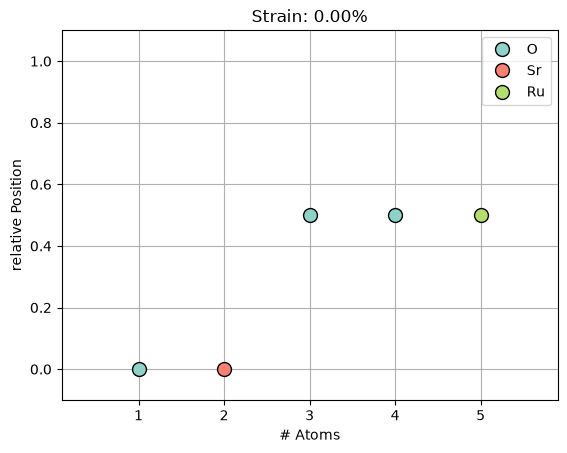

In [31]:
SRO.visualize()

## Structure

The {py:class}`AmorphousLayer <udkm1Dsim.structures.layers.AmorphousLayer>` and {py:class}`UnitCell <udkm1Dsim.structures.layers.UnitCell>` can now be added to an actual {py:class}`Structure <udkm1Dsim.structures.structure.Structure>`:

times,sub-structure,thickness
100,Strontium Ruthenate,39.49 nm
1000,Strontium Titanate Substrate,390.5 nm


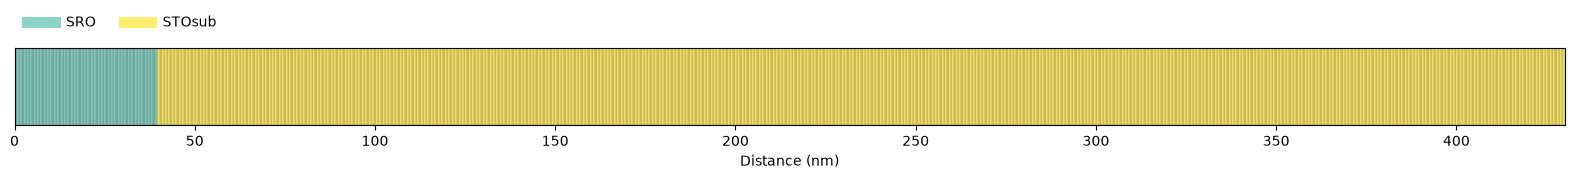

In [32]:
S = ud.Structure("Single Layer")
S.add_sub_structure(SRO, 100)  # add 100 layers of SRO to sample
S.add_sub_structure(STO_sub, 1000)  # add 1000 layers of STO substrate

display(S)

S.visualize()

There are various methods available to determine specific properties of a {py:class}`Structure <udkm1Dsim.structures.structure.Structure>`, please also refer to the {py:mod}`API documentation <udkm1Dsim.structures.structure>` for more details:

In [33]:
[d_start, d_end, d_mid] = S.layer_distances
K = S.num_sub_structures
L = S.num_unique_layers
M = S.num_layers
P = S.positions_per_unique_layer
I = S.interface_distances
c_axis = S.get_layer_property_vector("c_axis")

The {py:class}`Structure <udkm1Dsim.structures.structure.Structure>` class also allows to nest multiple substructures in order to build more complex samples easily:

Structure properties:

Name   : Super Lattice
Thickness : 332.6 nm
----
sub-structure 10 times:
	Structure properties:

	Name   : Double Layer
	Thickness : 13.73 nm
	----
	15 times Strontium Ruthenate: 5.923 nm
	20 times Strontium Titanate Substrate: 7.81 nm
	----
500 times Strontium Titanate Substrate: 195.2 nm
----
Superstrate (semi-infinite):
----
1 times vacuum: 1 nm
----
Substrate (semi-infinite):
----
1 times vacuum: 1 nm

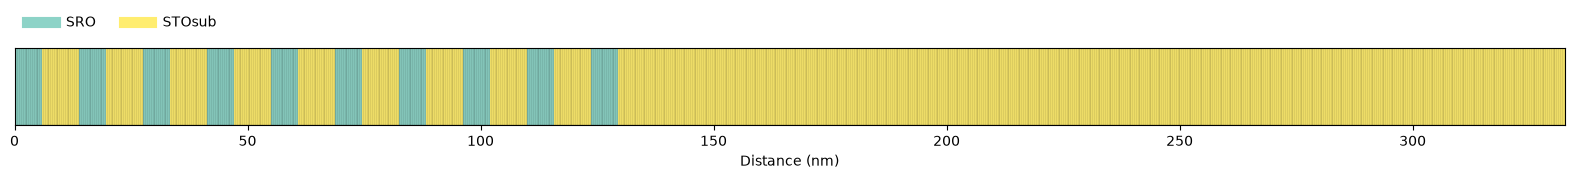

In [34]:
S2 = ud.Structure("Super Lattice")
# define a single double layer
DL = ud.Structure("Double Layer")
DL.add_sub_structure(SRO, 15)  # add 15 layers of SRO
DL.add_sub_structure(STO_sub, 20)  # add 20 layers of STO substrate

# add the double layer to the super lattice
S2.add_sub_structure(DL, 10)  # add 10 double layers to super lattice
S2.add_sub_structure(STO_sub, 500)  # add 500 layers of STO substrate

display(S2)

S2.visualize()

There a few more interfaces than before (includes also the top and bottom interface):

In [35]:
I2 = S2.interface_distances
len(I2)

21

## Superstrate & Substrate

For light and X-ray simulations it is often beneficial to add a static `superstrate` and `substrate` to the {py:class}`Structure <udkm1Dsim.structures.structure.Structure>`. By default, this is {py:class}`Vacuum <udkm1Dsim.structures.layers.Vacuum>`.

:::{important}
The `superstrate` and `substrate` are both **not included** into any time-resolved simulations, from e.g. {py:class}`Heat <udkm1Dsim.simulations.heat.Heat>`, {py:class}`Phonon <udkm1Dsim.simulations.phonons.Phonon>`, or {py:class}`Magnetization <udkm1Dsim.simulations.magnetization.Magnetization>`
:::

:::{note}
The `superstrate` and `substrate` are assumed to be **semi-infinite** which cancels any back-reflections e.g. for {py:class}`Elzo <udkm1Dsim.simulations.scattering.elzo.Elzo>`

For {py:class}`XrayKin <udkm1Dsim.simulations.scattering.kinematical.XrayKin>` and {py:class}`XrayDyn <udkm1Dsim.simulations.scattering.dynamical.XrayDyn>` however, one needs to define a finite number of {py:class}`UnitCell <udkm1Dsim.structures.layers.UnitCell>`s to achieve a typical *substrate Bragg peak*
:::

:::{versionchanged} 2.5.0

The `superstrate` and `substrate` can be only of type {py:class}`Layer <udkm1Dsim.structures.layers.Layer>` and its sub-classes.
It is possible to provide an integer $N$ for multiple repetitions, i.e. for `UnitCell <udkm1Dsim.structures.layers.UnitCell>`s.
Their default is {py:class}`Vacuum <udkm1Dsim.structures.layers.Vacuum>`

:::

Structure properties:

Name   : Super Lattice
Thickness : 332.6 nm
----
sub-structure 10 times:
	Structure properties:

	Name   : Double Layer
	Thickness : 13.73 nm
	----
	15 times Strontium Ruthenate: 5.923 nm
	20 times Strontium Titanate Substrate: 7.81 nm
	----
500 times Strontium Titanate Substrate: 195.2 nm
----
Superstrate (semi-infinite):
----
1 times vacuum: 1 nm
----
Substrate (semi-infinite):
----
1000000 times Strontium Titanate Substrate: 3.905×10⁵ nm

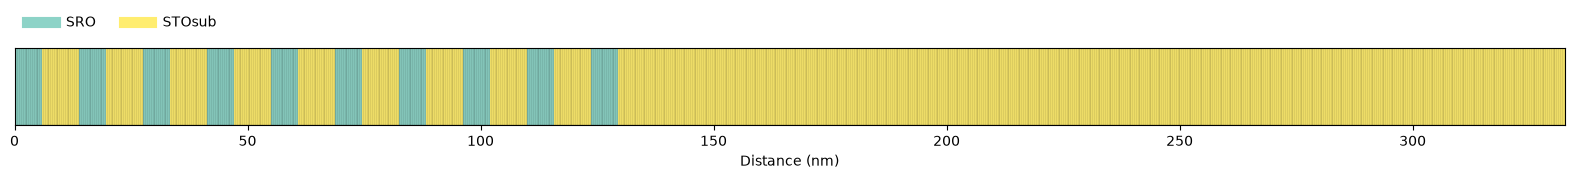

In [36]:
S2.add_substrate(STO_sub, 1000000)

display(S2)

S2.visualize()

## Save and Load

:::{versionadded} 3.0.0
:::

A {py:class}`Structure <udkm1Dsim.structures.structure.Structure>` can be saved as human-readable YAML by {py:meth}`to_yaml() <udkm1Dsim.structures.structure.Structure.to_yaml>`, e.g. in order to share or archive the sample of a publication, and loaded again by {py:meth}`from_yaml() <udkm1Dsim.structures.structure.Structure.from_yaml>`.
All atoms, layers, and nested structures are written once by their id and referenced in the sub-structures, as they are shared objects.
Only the parameters, which differ from their defaults, are written with their units, while the temperature-dependent parameters are written as their formula strings.
Dispersions are written by their source, e.g. the refractive index, a file, or a page of [refractiveindex.info](https://refractiveindex.info), and with `embed=True` by their tabulated values, so that the YAML is self-contained.

Without filename, the YAML text is returned:

In [37]:
text = S2.to_yaml()
print(text)

format_version: 1
udkm1Dsim_version: 3.0.0a3
atoms:
  O:
    symbol: O
  Sr:
    symbol: Sr
  Ru:
    symbol: Ru
  Ti:
    symbol: Ti
layers:
  SRO:
    type: UnitCell
    name: Strontium Ruthenate
    lattice:
      a_axis: 3.905 Å
      b_axis: 3.905 Å
      c_axis: 3.94897 Å
    thermal:
      therm_cond: 5.72 W/K/m
      heat_capacity: 0.112*T + 455.2 - 2193500.0/T**2
      lin_therm_exp: 1.03e-05
    elastic:
      sound_vel: 6.312 nm/ps
    optical:
      dielectric:
        ref_index: 2.44+4.32j
    atoms:
    - [O, 0]
    - [Sr, 0]
    - [O, 0.5]
    - [O, 0.5]
    - [Ru, 0.5]
  STOsub:
    type: UnitCell
    name: Strontium Titanate Substrate
    lattice:
      c_axis: 3.905 Å
    thermal:
      therm_cond: 12.0 W/K/m
      heat_capacity: 0.0248*T + 733.73 - 6531000.0/T**2
      lin_therm_exp: 1.0e-05
    elastic:
      sound_vel: 7.8 nm/ps
    optical:
      dielectric:
        ref_index: 2.1
    atoms:
    - [Sr, 0]
    - [O, 0.1*(s**2+1)]
    - [O, 0.5]
    - [O, 0.5]
    -

With a filename, e.g. `S2.to_yaml("super_lattice.yml")`, the YAML is written to a file, which can be edited in any text editor and is read by `ud.Structure.from_yaml("super_lattice.yml")`, where the paths of files are relative to the YAML file.
Here, the structure is read from the YAML text instead.

On writing, the YAML is read back and compared, so that the loaded structure has the same hash, and hence the cached simulation results are found again:

In [38]:
S3 = ud.Structure.from_yaml(text)

print(S2.get_hash(types="heat"))
print(S3.get_hash(types="heat"))

display(S3)

c5e3303e4244570d918ce42b52c1318e
c5e3303e4244570d918ce42b52c1318e


Structure properties:

Name   : Super Lattice
Thickness : 332.6 nm
----
sub-structure 10 times:
	Structure properties:

	Name   : Double Layer
	Thickness : 13.73 nm
	----
	15 times Strontium Ruthenate: 5.923 nm
	20 times Strontium Titanate Substrate: 7.81 nm
	----
500 times Strontium Titanate Substrate: 195.2 nm
----
Superstrate (semi-infinite):
----
1 times vacuum: 1 nm
----
Substrate (semi-infinite):
----
1000000 times Strontium Titanate Substrate: 3.905×10⁵ nm